GaussianNB accuracy: 0.9385964912280702


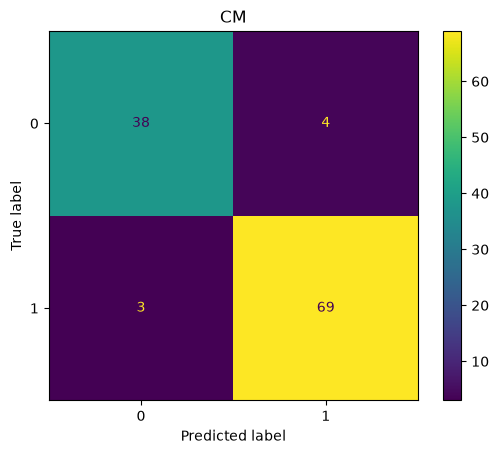

[1]


In [1]:
# ===================== REVISION / ONE-SHOT: NAIVE BAYES =====================
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# 1) Continuous features -> GaussianNB
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = GaussianNB().fit(X_train, y_train)
y_pred = model.predict(X_test)
print("GaussianNB accuracy:", accuracy_score(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred); plt.title("CM"); plt.show()

# 2) Text -> clean -> vectorize -> MultinomialNB
texts = ["Great movie, loved it!", "Worst film ever.", "Loved the acting", "Boring and bad"]
labels = [1, 0, 1, 0]
clean = [re.sub(r"[^a-z\s]", "", t.lower()) for t in texts]     # lowercase + drop punctuation
vec = CountVectorizer(stop_words="english")                     # or TfidfVectorizer()
X_text = vec.fit_transform(clean)                               # sparse word-count matrix
nb = MultinomialNB().fit(X_text, labels)
print(nb.predict(vec.transform(["loved this great film"])))

# ---------------- VIVA NOTES ----------------
# Bayes rule: P(class | x) is proportional to P(x | class) * P(class); "naive" = features assumed independent.
# GaussianNB: continuous features (each feature normal per class). MultinomialNB: word counts / TF-IDF.
# BernoulliNB: binary features. alpha (Laplace smoothing) avoids zero probability for unseen words.
# Fast, works well on text and small data, gives probabilities with predict_proba.
# Vectorizer: fit on train only, then transform test (same vocabulary).
# Read CM: diagonal = correct, off diagonal = mistakes (FP / FN).

### Q44

The breast cancer dataset is available in the sklearn.datasets module and can be loaded using load_breast_cancer(). implement a Naive Bayes Classifier on the Breast Cancer Dataset using python's sklearn library. Assume that all features of datasets are continuous variables and must be used for building model. Perform following task. load data set, Split data for training and testing, Build a model and Predict labels of test data.

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [3]:
# Load dataset (all 30 continuous features)
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target
print("X shape:", X.shape, "| classes:", cancer.target_names.tolist())

X shape: (569, 30) | classes: ['malignant', 'benign']


In [4]:
# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (455, 30) | Test: (114, 30)


In [5]:
# Gaussian NB for continuous features, predict test labels
model = GaussianNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Predicted labels (first 20):", y_pred[:20])
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

Predicted labels (first 20): [0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1]
Accuracy: 0.9385964912280702
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



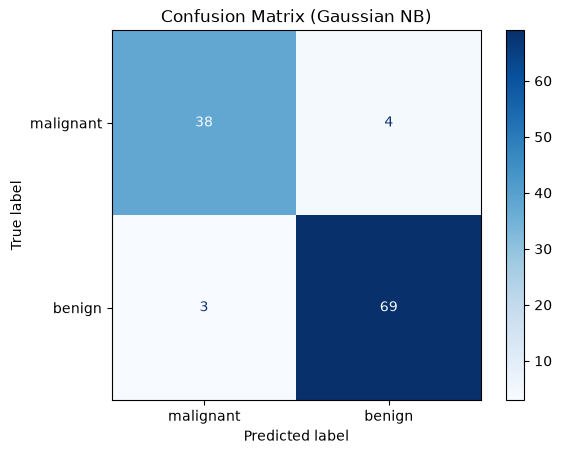

In [6]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=cancer.target_names, cmap="Blues")
plt.title("Confusion Matrix (Gaussian NB)")
plt.show()

### Q45

Implement a Gaussian Naive Bayes classifier to predict whether a patient has diabetes based on various health metrics of PIMA.csv dataset. The dataset consists of information from 768 female Pima Indians aged 21 and older, initially gathered by the National Institute of Diabetes and Digestive and Kidney Diseases. Target variable: Diabetes (binary, 0 or 1) Attributes: Pregnancies, OGTT (Oral Glucose Tolerance Test), Blood pressure, Skin thickness, Insulin, BMI (Body Mass Index), Age, Pedigree diabetes function.Load the Dataset from a CSV file. Provide summary statistics for the dataset. Split the data into training and testing sets (80% train, 20% test). Instantiate a Gaussian Naive Bayes model and fit it on the training data. Predict diabetes status for the test set. Discuss any biases in the dataset and how they may affect model performance

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [8]:
# Load CSV (target column is 'Outcome')
df = pd.read_csv("datasets/PIMA.csv")
print(df.shape)
print(df.head())

(768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [9]:
# Summary statistics
print(df.describe().T.round(2))
print("\nMissing values:", df.isnull().sum().sum())

                          count    mean     std    min    25%     50%     75%  \
Pregnancies               768.0    3.85    3.37   0.00   1.00    3.00    6.00   
Glucose                   768.0  120.89   31.97   0.00  99.00  117.00  140.25   
BloodPressure             768.0   69.11   19.36   0.00  62.00   72.00   80.00   
SkinThickness             768.0   20.54   15.95   0.00   0.00   23.00   32.00   
Insulin                   768.0   79.80  115.24   0.00   0.00   30.50  127.25   
BMI                       768.0   31.99    7.88   0.00  27.30   32.00   36.60   
DiabetesPedigreeFunction  768.0    0.47    0.33   0.08   0.24    0.37    0.63   
Age                       768.0   33.24   11.76  21.00  24.00   29.00   41.00   
Outcome                   768.0    0.35    0.48   0.00   0.00    0.00    1.00   

                             max  
Pregnancies                17.00  
Glucose                   199.00  
BloodPressure             122.00  
SkinThickness              99.00  
Insulin       

In [10]:
# Split 80/20
X = df.drop("Outcome", axis=1)
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Accuracy: 0.7078
              precision    recall  f1-score   support

           0       0.80      0.74      0.77       100
           1       0.57      0.65      0.61        54

    accuracy                           0.71       154
   macro avg       0.68      0.69      0.69       154
weighted avg       0.72      0.71      0.71       154



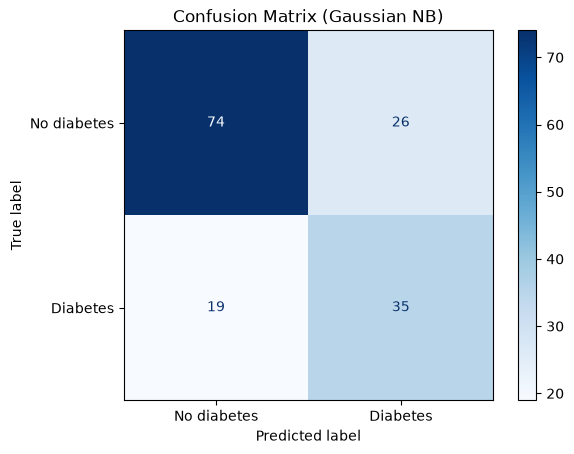

In [11]:
# Gaussian NB
model = GaussianNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No diabetes", "Diabetes"], cmap="Blues")
plt.title("Confusion Matrix (Gaussian NB)")
plt.show()

In [12]:
# Bias check 1: class imbalance
print("Class balance (%):")
print((y.value_counts(normalize=True) * 100).round(1))

# Bias check 2: impossible zeros (really missing values)
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("\nZero values per column:")
print((df[cols] == 0).sum())

Class balance (%):
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64

Zero values per column:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [13]:
# Discussion of biases:
# 1. Class imbalance (~65% no diabetes): model leans to predicting "no", so recall for diabetics is lower.
# 2. Zeros in Glucose, BP, SkinThickness, Insulin, BMI are missing values; they distort the Gaussian
#    mean/variance of each class. Fix: replace zeros with the median.
# 3. Population bias: only female Pima Indians aged 21+, so results may not generalize to men or other groups.
# 4. Naive independence assumption is broken (Glucose/Insulin, BMI/SkinThickness are correlated),
#    so probabilities are over-confident.
# 5. Small dataset (768 rows) means the test score varies with the split; use cross-validation.

### Q46

Build a Naive Bayes classifier to analyze the sentiment of movie reviews (positive or negative). The IMDB_Dataset.csv typically contains two main columns: Review: The text of the movie review. Sentiment: A label indicating the sentiment of the review, usually categorized as 'positive' or 'negative'. Load the dataset and inspect the structure. Clean the text data by removing punctuation, converting to lowercase, and tokenizing the reviews.Use CountVectorizer or TfidfVectorizer to convert the text data into a numerical format suitable for model training. Split the dataset and Create a Multinomial Naive Bayes model and fit it on the training data. Predict the sentiment of the test reviews.

In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [ ]:
# Load and inspect (Kaggle IMDB file uses lowercase column names 'review' and 'sentiment')
df = pd.read_csv("datasets/IMDB_Dataset.csv")
df.columns = df.columns.str.lower()          # works for 'Review' / 'review' alike
print(df.shape)
print(df.head())
print(df["sentiment"].value_counts())

In [ ]:
# Clean: remove HTML tags, lowercase, remove punctuation, tokenize
def clean_text(text):
    text = re.sub(r"<.*?>", " ", text)          # remove <br /> etc.
    text = text.lower()                          # lowercase
    text = re.sub(r"[^a-z\s]", "", text)         # keep only letters and spaces
    tokens = text.split()                        # tokenize into words
    return " ".join(tokens)

df["clean"] = df["review"].apply(clean_text)
print(df[["review", "clean"]].head(3))

In [ ]:
# Split, then vectorize (fit vocabulary on train only)
X = df["clean"]
y = df["sentiment"].map({"positive": 1, "negative": 0})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
vec = CountVectorizer(stop_words="english")
X_train = vec.fit_transform(X_train)
X_test = vec.transform(X_test)
print("Vocabulary size:", len(vec.vocabulary_))

In [ ]:
# Multinomial NB
model = MultinomialNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=["negative", "positive"]))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["negative", "positive"], cmap="Blues")
plt.title("Confusion Matrix (Multinomial NB)")
plt.show()

In [ ]:
# Predict sentiment of new reviews
new = ["What a fantastic movie, brilliant acting!", "Terrible plot, I wasted my time."]
pred = model.predict(vec.transform([clean_text(t) for t in new]))
for t, p in zip(new, pred):
    print(t, "->", "positive" if p == 1 else "negative")

### Q47

Use sklearn.datasets.fetch_20newsgroups() dataset (all sets) to classify newsgroup documents into their respective categories using a Multinomial Naive Bayes classifier. Load the dataset and explore the categories available. Preprocess the text data using CountVectorizer to convert text documents into a matrix of token counts. Split the dataset and Create a Multinomial Naive Bayes model. Fit the model on the training data and print accuracy.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

In [21]:
# Needs internet the first time (downloads ~14 MB, then cached)
data = fetch_20newsgroups(subset="all", remove=("headers", "footers", "quotes"))
print("Documents:", len(data.data))
print("Categories:", len(data.target_names))
for i, name in enumerate(data.target_names):
    print(i, name)

Documents: 18846
Categories: 20
0 alt.atheism
1 comp.graphics
2 comp.os.ms-windows.misc
3 comp.sys.ibm.pc.hardware
4 comp.sys.mac.hardware
5 comp.windows.x
6 misc.forsale
7 rec.autos
8 rec.motorcycles
9 rec.sport.baseball
10 rec.sport.hockey
11 sci.crypt
12 sci.electronics
13 sci.med
14 sci.space
15 soc.religion.christian
16 talk.politics.guns
17 talk.politics.mideast
18 talk.politics.misc
19 talk.religion.misc


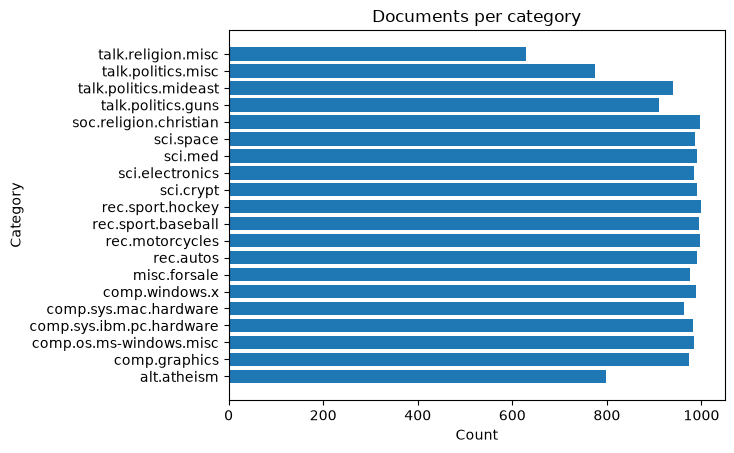

In [22]:
# Documents per category
counts = np.bincount(data.target)
plt.barh(data.target_names, counts)
plt.title("Documents per category")
plt.xlabel("Count")
plt.ylabel("Category")
plt.show()

In [23]:
# Split, then CountVectorizer (token counts)
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.2,
                                                    random_state=42, stratify=data.target)
vec = CountVectorizer(stop_words="english", max_features=20000)
X_train = vec.fit_transform(X_train)
X_test = vec.transform(X_test)
print("Train matrix:", X_train.shape)

Train matrix: (15076, 20000)


In [24]:
# Multinomial NB
model = MultinomialNB(alpha=0.1)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

Accuracy: 0.6886
